
# Wine Classification Using Decision Trees

## Objective
Classify wine samples into three classes using a Decision Tree Classifier.

## Experiments
- Compare Gini and Entropy criteria.
- Test max_depth values of 2, 4, and 6.
- Evaluate each model using accuracy.
- Visualize the decision tree.
- Identify the best-performing parameter combination.


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")


In [2]:

wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="target")

df = X.copy()
df["target"] = y

print("Dataset shape:", df.shape)
print("Number of features:", X.shape[1])
print("Number of classes:", y.nunique())
print("\nClass names:", wine.target_names)
print("\nClass distribution:")
print(y.value_counts().sort_index())

display(df.head())


Dataset shape: (178, 14)
Number of features: 13
Number of classes: 3

Class names: ['class_0' 'class_1' 'class_2']

Class distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Missing values:
0

Feature summary:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


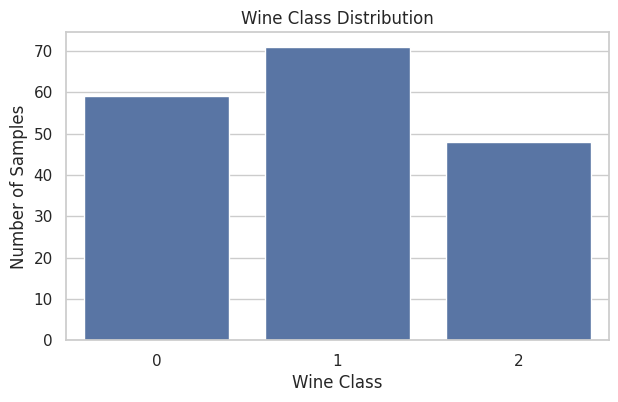

In [3]:

print("Missing values:")
print(X.isnull().sum().sum())

print("\nFeature summary:")
display(X.describe().T)

plt.figure(figsize=(7, 4))
sns.countplot(x=y)
plt.title("Wine Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.show()


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 142
Testing samples: 36


In [5]:

results = []
models = {}

for criterion in ["gini", "entropy"]:
    for depth in [2, 4, 6]:
        model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        accuracy = accuracy_score(y_test, y_pred)

        results.append({
            "Criterion": criterion,
            "Max Depth": depth,
            "Accuracy": accuracy
        })

        models[(criterion, depth)] = model

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))


,Criterion,Max Depth,Accuracy
0,entropy,2,1.0000
1,entropy,4,0.9722
2,entropy,6,0.9722
3,gini,4,0.9444
4,gini,6,0.9444
5,gini,2,0.8611


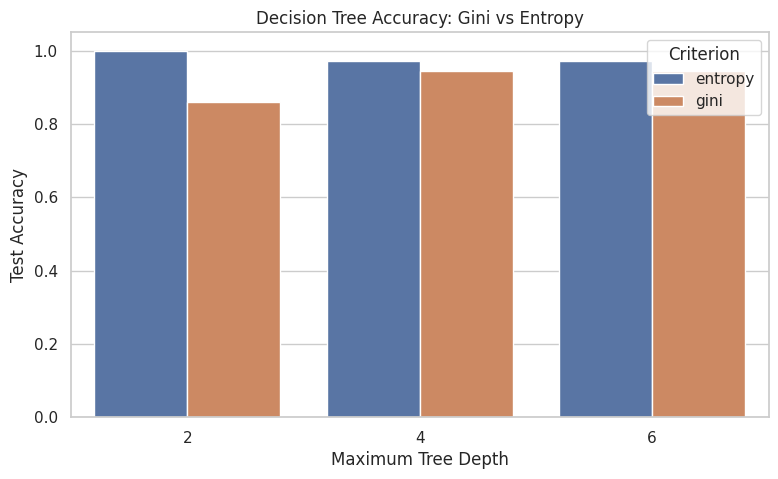

In [6]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Max Depth",
    y="Accuracy",
    hue="Criterion"
)

plt.title("Decision Tree Accuracy: Gini vs Entropy")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1.05)
plt.legend(title="Criterion")
plt.show()


In [7]:

best_row = results_df.iloc[0]

best_criterion = best_row["Criterion"]
best_depth = int(best_row["Max Depth"])
best_accuracy = best_row["Accuracy"]

best_model = models[(best_criterion, best_depth)]

print("Best Criterion:", best_criterion)
print("Best Max Depth:", best_depth)
print(f"Best Test Accuracy: {best_accuracy:.4f}")
print(f"Best Test Accuracy: {best_accuracy * 100:.2f}%")


Best Criterion: entropy
Best Max Depth: 2
Best Test Accuracy: 1.0000
Best Test Accuracy: 100.00%


Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



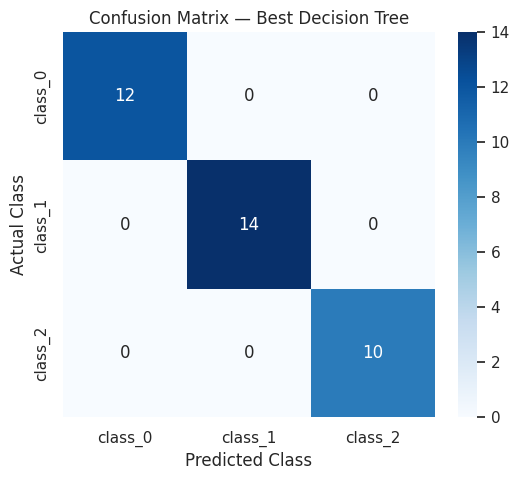

In [8]:

y_pred_best = best_model.predict(X_test)

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=wine.target_names
    )
)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=wine.target_names,
    yticklabels=wine.target_names
)

plt.title("Confusion Matrix — Best Decision Tree")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


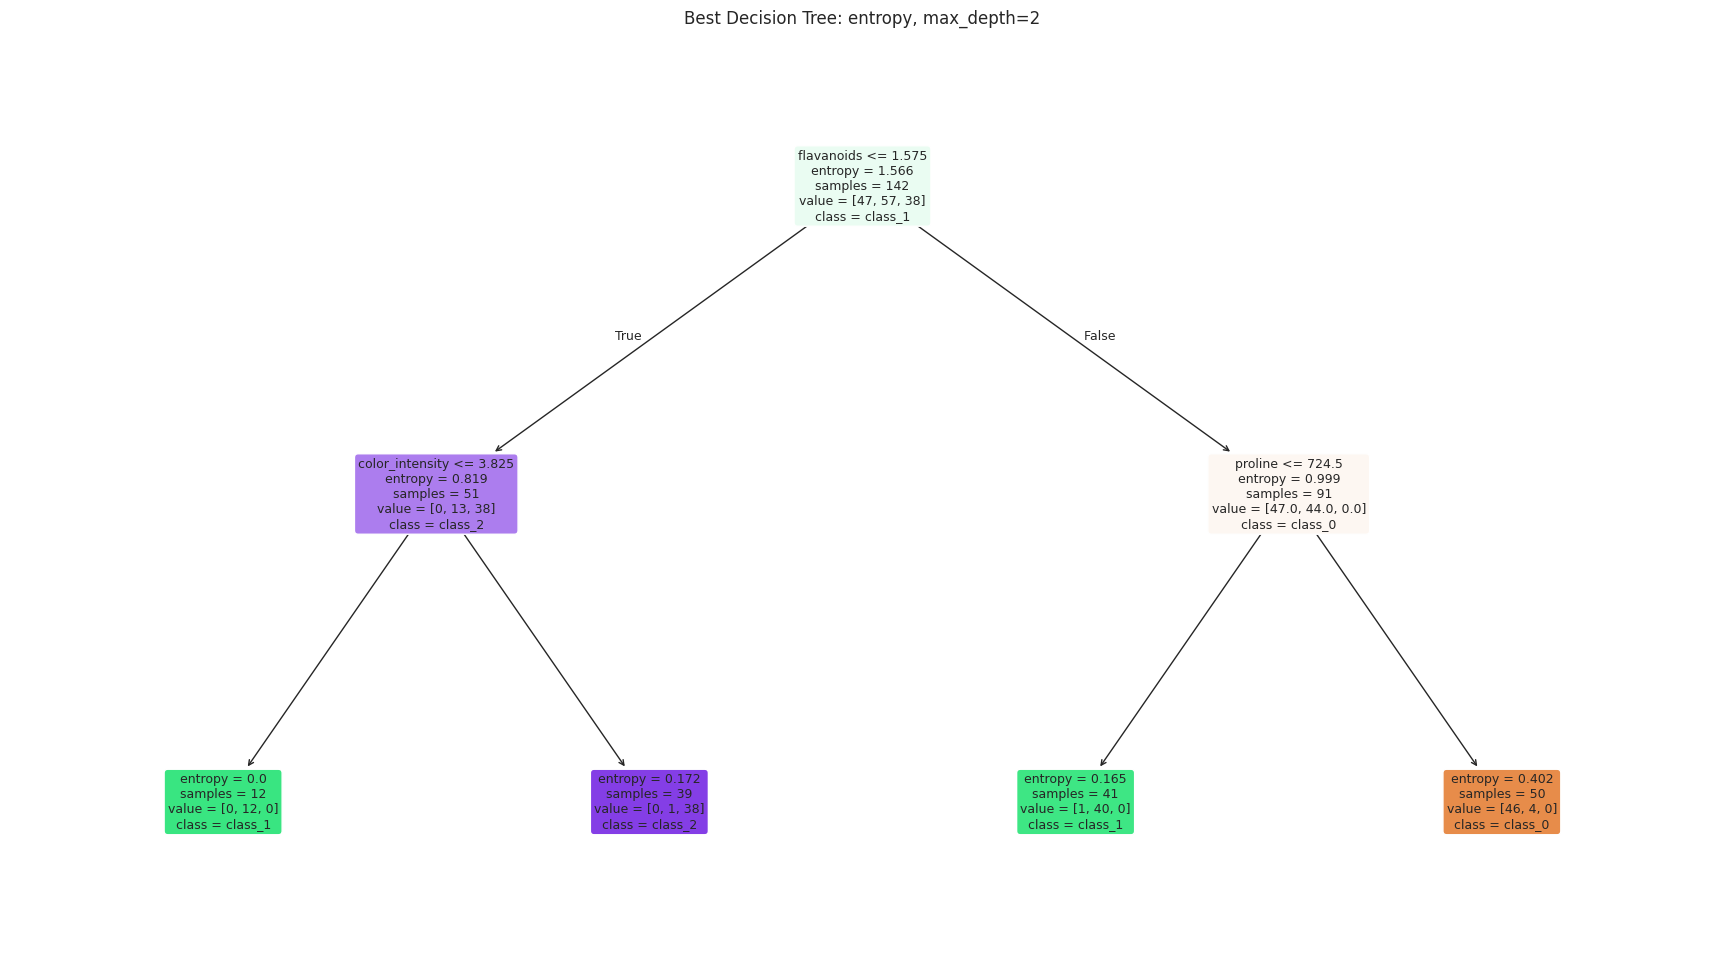

In [9]:

plt.figure(figsize=(22, 12))

plot_tree(
    best_model,
    feature_names=wine.feature_names,
    class_names=wine.target_names,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title(
    f"Best Decision Tree: {best_criterion}, max_depth={best_depth}"
)
plt.show()


,Feature,Importance
6,flavanoids,0.474861
12,proline,0.339357
9,color_intensity,0.185782
1,malic_acid,0.000000
0,alcohol,0.000000
4,magnesium,0.000000
3,alcalinity_of_ash,0.000000
2,ash,0.000000
5,total_phenols,0.000000
8,proanthocyanins,0.000000


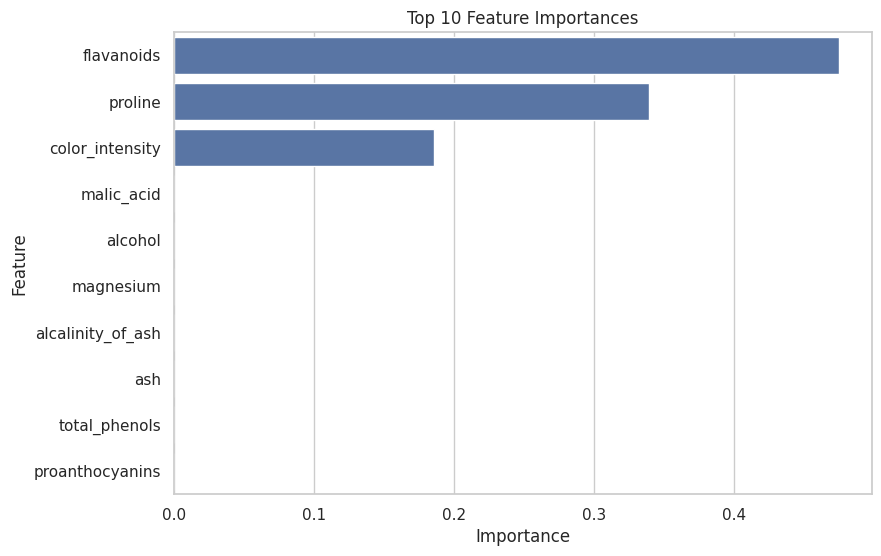

In [10]:

importance_df = pd.DataFrame({
    "Feature": wine.feature_names,
    "Importance": best_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()


In [11]:

print("FINAL EXPERIMENT SUMMARY")
print("-" * 35)

for _, row in results_df.iterrows():
    print(
        f"Criterion: {row['Criterion']:7s} | "
        f"Max Depth: {int(row['Max Depth'])} | "
        f"Accuracy: {row['Accuracy']:.4f}"
    )

print("\nBest configuration:")
print("Criterion:", best_criterion)
print("Max Depth:", best_depth)
print(f"Accuracy: {best_accuracy:.4f}")


FINAL EXPERIMENT SUMMARY
-----------------------------------
Criterion: entropy | Max Depth: 2 | Accuracy: 1.0000
Criterion: entropy | Max Depth: 4 | Accuracy: 0.9722
Criterion: entropy | Max Depth: 6 | Accuracy: 0.9722
Criterion: gini    | Max Depth: 4 | Accuracy: 0.9444
Criterion: gini    | Max Depth: 6 | Accuracy: 0.9444
Criterion: gini    | Max Depth: 2 | Accuracy: 0.8611

Best configuration:
Criterion: entropy
Max Depth: 2
Accuracy: 1.0000
